# Teaching a classroom of neural networks

**Sierra Janson** · Lab for Human Mathematics · research spring 2024, rebuilt 2026 with Claude!

**Question.** If students were small neural networks, would they learn better studying
alone, studying in groups, or following a group leader? And does the answer change between
*reproducing what they were shown* and *applying it somewhere new*?

**Setup in one paragraph.** A class of 24 "students" (one-hidden-layer tanh networks with
4–16 neurons each) learns a concept, which is a polynomial on $[0, 1]$. Each student takes their
own **notes**: 8 noisy observations at random points in $[0, 0.7]$. Students are graded on
**homework** (their own notes), a **quiz** (new points inside $[0, 0.7]$, i.e. interpolation)
and a **final exam** on $(0.7, 1]$, a region nobody took notes on (extrapolation). Three
teaching strategies are compared under identical conditions: same students, same starting
weights, same notes, same optimiser and same study time. Only the strategy changes.

The code lives in the `classroom/` package and is covered by tests in `tests/`.

In [1]:
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import torch

from classroom import CONCEPTS, make_lesson
from classroom.experiment import (ExperimentConfig, paired_differences, read_csv, run_all,
                                  run_trial, summarize, write_csv)
from classroom.plots import (apply_style, plot_grade_spread, plot_grades, plot_group_predictions,
                             plot_lesson)

torch.set_num_threads(1)
apply_style()
cfg = ExperimentConfig()
print(cfg)

ExperimentConfig(n_students=24, n_notes=8, noise=0.05, train_max=0.7, hidden_low=4, hidden_high=16, seeds=[0, 1, 2, 3, 4], train=TrainConfig(group_size=4, epochs=3000, lr=0.01, peer_weight=1.0, leader_warmup=0.3333333333333333))


## 1. The lesson

The three concepts are the same polynomials used in the original 2024 notebooks.
The shaded region is never shown to anyone in class; it only appears on the final exam.

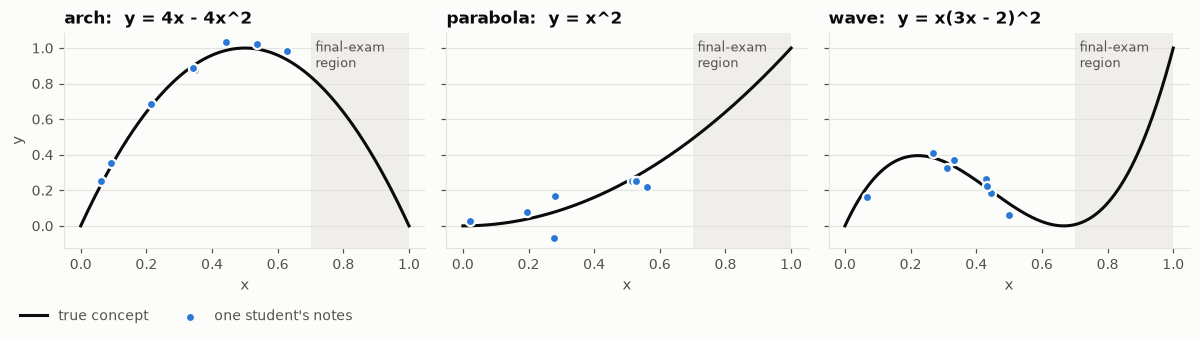

In [2]:
lessons = {
    c.name: make_lesson(c, cfg.n_students, cfg.n_notes, cfg.noise, cfg.train_max,
                        torch.Generator().manual_seed(ci))  # = seed 0 of the experiment
    for ci, c in enumerate(CONCEPTS)
}
plot_lesson(lessons, cfg.train_max);

With only 8 noisy points, a single student can't tell the concept apart from the noise in
their notes. Classmates' notes contain different points and different noise, so in
principle the class as a whole knows much more than any one student. Each strategy is a
different way of letting (or not letting) that knowledge flow between students.

## 2. Teaching strategies

Students are split into study groups of 4. Write $f_s$ for student $s$'s network,
$\mathcal{N}_s$ for their notes, and $\mathcal{P}_g$ for all the $x$-values in group $g$'s pooled notes.

| Strategy | Each student minimises | Idea |
|---|---|---|
| **Lecture** | $\displaystyle \underbrace{\tfrac{1}{\lvert\mathcal N_s\rvert}\sum_{(x,y)\in\mathcal N_s} (f_s(x)-y)^2}_{\text{own-notes MSE}}$ | Study alone |
| **Group study** | own-notes MSE $\;+\;\lambda\,\tfrac{1}{\lvert\mathcal P_g\rvert}\sum_{x\in\mathcal P_g}\big(f_s(x) - \overline{f}_{-s}(x)\big)^2$ | Match the average answer $\overline f_{-s}$ of your groupmates (Deep Mutual Learning) |
| **Leader** | own-notes MSE $\;+\;\lambda\,\tfrac{1}{\lvert\mathcal P_g\rvert}\sum_{x\in\mathcal P_g}\big(f_s(x) - f_{\text{leader}}(x)\big)^2$ | After a solo warm-up (1/3 of study time), the student who best explains the *other* members' notes leads; followers learn from them (knowledge distillation) |

Peers' answers are treated as fixed targets (no gradient flows into the peer). $\lambda = 1$ throughout.
Everyone trains with Adam (learning rate 0.01) for 3000 full-batch steps.

### What happened to the 2024 "active learning"?

The original notebook let groups back-propagate the **sum** of their members' losses. That
looks collaborative, but student $s$'s weights only appear in their own term of the sum, so
$\partial(\sum_k L_k)/\partial \theta_s = \partial L_s / \partial \theta_s$. Each student
gets exactly their solo gradient and nobody learns anything from anyone else. The experiment
keeps it as a control strategy, `shared_loss_2024`, and the tests check this identity. You can
check it below too:

In [3]:
from classroom import Classroom

lesson = lessons["wave"]
model = Classroom([8] * cfg.n_students, generator=torch.Generator().manual_seed(0))
own = ((model(lesson.notes_x) - lesson.notes_y) ** 2).mean(dim=(1, 2))   # each student's loss
shared = own.reshape(-1, 4).sum(dim=1).sum()                               # 2024: sum within groups

g_shared = torch.autograd.grad(shared, model.w1, retain_graph=True)[0][5]
g_solo = torch.autograd.grad(own[5], model.w1)[0][5]
print("student 5, gradient under shared loss == gradient studying alone:",
      torch.allclose(g_shared, g_solo))

student 5, gradient under shared loss == gradient studying alone: True


## 3. Results

The full experiment runs 5 independent classes (seeds) × 3 concepts × 4 strategies, about
15 minutes on a laptop CPU. It's run with `python -m classroom.experiment`, which writes
one row per student to `results/students.csv`; this notebook loads that file. Set
`RERUN = True` to regenerate it here instead.

In [4]:
RERUN = False
results_path = Path("results/students.csv")
if RERUN or not results_path.exists():
    rows = run_all(cfg)
    write_csv(rows, results_path)
else:
    rows = read_csv(results_path)
print(f"{len(rows)} student results loaded")

summary = summarize(rows)
names = {"lecture": "Lecture", "shared_loss_2024": "Shared loss (2024)",
         "group_study": "Group study", "leader": "Leader"}
for concept in [c.name for c in CONCEPTS] + ["all"]:
    print(f"\n{'ALL THREE CONCEPTS' if concept == 'all' else concept.upper()}"
          f"   class-average grade, mean +/- std over {len(cfg.seeds)} classes")
    print(f"  {'strategy':<20}{'homework':>15}{'quiz':>15}{'exam':>15}")
    for strat, label in names.items():
        cells = summary[(concept, strat)]
        print(f"  {label:<20}" + "".join(f"{cells[a][0]:>9.1f} +/- {cells[a][1]:<3.1f}"
                                         for a in ("homework", "quiz", "exam")))

1440 student results loaded

ARCH   class-average grade, mean +/- std over 5 classes
  strategy                   homework           quiz           exam
  Lecture                  98.8 +/- 0.1     92.2 +/- 2.7     17.4 +/- 7.4
  Shared loss (2024)       98.8 +/- 0.1     92.2 +/- 2.7     17.4 +/- 7.4
  Group study              98.3 +/- 0.2     99.1 +/- 0.2     14.4 +/- 4.7
  Leader                   98.0 +/- 0.5     97.9 +/- 0.8     21.1 +/- 5.3

PARABOLA   class-average grade, mean +/- std over 5 classes
  strategy                   homework           quiz           exam
  Lecture                  98.6 +/- 0.1     95.3 +/- 2.1     44.4 +/- 8.6
  Shared loss (2024)       98.6 +/- 0.1     95.3 +/- 2.1     44.4 +/- 8.6
  Group study              98.1 +/- 0.2     99.3 +/- 0.1     74.5 +/- 8.1
  Leader                   98.0 +/- 0.2     98.4 +/- 0.5     57.6 +/- 7.1

WAVE   class-average grade, mean +/- std over 5 classes
  strategy                   homework           quiz           exam
 

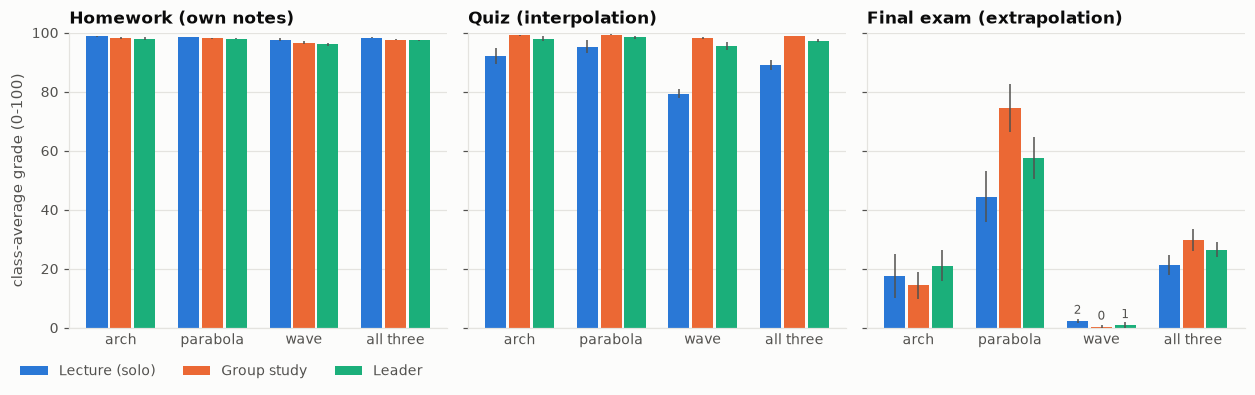

In [5]:
plot_grades(summary);

Because every strategy is run on the very same classes, the cleanest comparison is
**paired**: for each class, take the difference from lecture learning, then look at how
consistent that difference is across the 5 classes.

In [6]:
diffs = paired_differences(rows)
print(f"{'strategy':<20}{'assessment':<11}{'change vs lecture':>20}{'classes improved':>18}")
for (strat, a), (mean, std, better, n) in diffs.items():
    print(f"{names[strat]:<20}{a:<11}{mean:>+12.1f} +/- {std:<4.1f}{better:>11} / {n}")

strategy            assessment    change vs lecture  classes improved
Group study         homework           -0.7 +/- 0.2           0 / 5
Group study         quiz               +9.9 +/- 1.7           5 / 5
Group study         exam               +8.3 +/- 4.1           5 / 5
Leader              homework           -1.0 +/- 0.2           0 / 5
Leader              quiz               +8.3 +/- 1.8           5 / 5
Leader              exam               +5.1 +/- 2.6           5 / 5
Shared loss (2024)  homework           +0.0 +/- 0.0           2 / 5
Shared loss (2024)  quiz               +0.0 +/- 0.0           2 / 5
Shared loss (2024)  exam               -0.0 +/- 0.1           3 / 5


### What the students actually learned

One study group on the hardest concept (`wave`), in the first class. The same four students,
from the same starting weights, under each strategy:

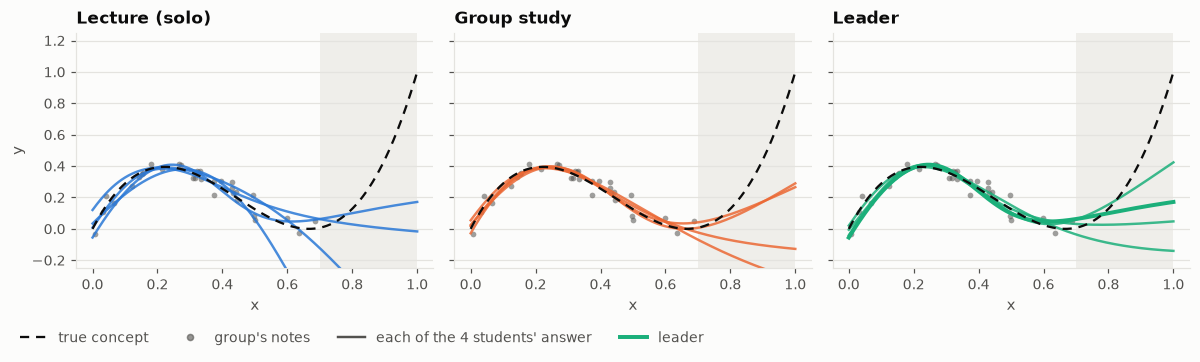

In [7]:
wave_idx = [c.name for c in CONCEPTS].index("wave")
trial_rows, trial = run_trial(CONCEPTS[wave_idx], wave_idx, seed=0, cfg=cfg,
                              strategies=("lecture", "group_study", "leader"))
leaders = {r["student"] for r in trial_rows if r["is_leader"]}
plot_group_predictions(trial, group=0, group_size=cfg.train.group_size, train_max=cfg.train_max,
                       concept=CONCEPTS[wave_idx], leaders=leaders);

### Who gets left behind?

Every student's quiz grade, pooled over all classes and concepts:

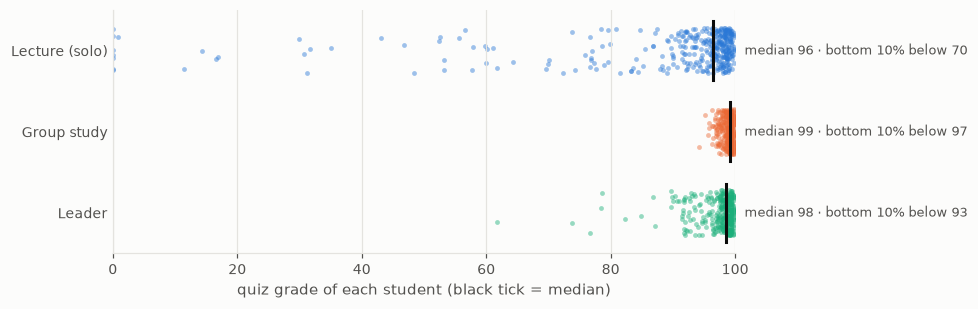

In [8]:
plot_grade_spread(rows, "quiz");

## 4. Discussion

**Learning from classmates helps on the quiz, and it helps the weakest students most.**
Studying alone, students score 98 on their own homework but only 89 on the quiz: with 8
noisy points each, many of them learn the noise in their notes. Group study raises the class
quiz average to 98.9 and the leader strategy to 97.2. Both beat lecture in every one of the 5
classes, by about +10 and +8 points. The averages understate the effect. Under lecture, the
bottom 10% of students score below 70 on the quiz and a few score 0. Under group study, the lowest
quiz grade of any student, across all classes and concepts, is 94. Matching your groupmates' answers works like a
regulariser: it averages out everyone's noise, and nobody can drift far on their own.

**The price is a slightly worse homework grade (about −1 point).** Students under the
collaborative strategies fit their own notes a little less closely because they're also
listening to their peers. In this setting that's the right trade, since the notes are noisy and
fitting them exactly is overfitting.

**The 2024 "shared loss" strategy is identical to studying alone,** to within ±0.1 grade
points on every assessment, as the gradient argument in section 2 predicts. The idea of
collaborative learning was sound, but that implementation never let the students interact.

**Followers overtake their leader.** The leader strategy does pick strong students: the
students chosen as leaders would have averaged 95.4 on the quiz studying alone, against a class
average of 89. But the followers end up *higher* than their leader (97.9 vs. 95.4), because each
of them combines the leader's answers with their own notes, while the leader only has one set
of notes. Group study, where everyone learns from everyone, does best of all.

**Nobody learns to extrapolate.** Final-exam grades stay low under every strategy (21–30
averaged over concepts). The pooled improvement from group study (+8 points, better in 5/5
classes) comes almost entirely from the parabola, which goes from 44 to 75. On the arch, group
study is slightly *worse* than lecture (14 vs. 17). On the wave, which turns sharply upward
right where the notes stop, every strategy scores about 0. Collaboration lowers variance on
what the class has seen; it can't supply information about a region nobody has seen. In the
original project's terms, these students got better at "memorization" and interpolation, but
"critical thinking" in the extrapolation sense is limited by the model itself (a small tanh
network has no reason to continue a polynomial's shape), not by how it is taught.

**Capacity barely matters here.** Quiz grades are about the same for students with 4–8,
9–12 and 13–16 hidden neurons under every strategy, so the gains come from the strategy,
not from which students happen to be bigger.

## 5. Limitations and next steps

* **Small, synthetic setting.** These are 1-D polynomials and tiny networks. The
  classroom framing is an analogy, not a model of human learning.
* **One hyperparameter setting.** $\lambda = 1$, group size 4, 8 notes and noise 0.05 were chosen
  up front and not tuned. Natural next experiments: sweep $\lambda$ (too high should collapse
  each group onto one shared answer), vary the noise level (does the collaborative advantage
  vanish when notes are clean?) and vary group size.
* **Study time.** All strategies get the same 3000 steps. Under lecture, quiz grades keep
  *falling* with longer training (overfitting), while the collaborative strategies are stable,
  so the gap would grow with more training rather than shrink.
* **Extrapolation needs a different tool.** Testing it fairly would mean giving students an
  inductive bias that can extrapolate (e.g. polynomial features), and then asking whether
  collaboration helps them *choose* the right one.